# Task 2 - 04 Evaluation

## Objective
Measure how well the saved model works on the **held-out test split** (images never used for training or model selection), and understand *where and why* it fails.

## Short theory
* **Accuracy** = correct predictions / all predictions.
* **Precision** (of the images predicted as class C, how many really are C) and **recall** (of the real C images, how many were found); **F1** = harmonic mean of both. Macro-averages treat every class equally.
* **Confusion matrix** - rows = true class, columns = predicted class; the diagonal is correct, off-diagonal cells show which classes get confused.
* **Grad-CAM** - highlights the image regions that most increased the score of the predicted class (an explanation of the model's decision).
* For an inspection assistant, *missing a rotten fruit* (rotten predicted as fresh) is the costly error.

In [1]:
# --- Setup: find the project root (the folder that contains "src") so imports work ---
import json
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from src.task2 import config

warnings.filterwarnings("ignore", category=FutureWarning)
config.ensure_out_dir()
print("Project root :", ROOT.name)
print("Data folder  :", config.DATA_DIR)
print("Output folder:", config.OUT_DIR)

import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from src.task2 import data_utils, dataset, predict, train_utils, transforms, viz

Project root : FCVG101_Coursework
Data folder  : C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\data\raw
Output folder: C:\Users\admin\Desktop\FundementalOfComputerVision\FCVG101_Coursework\Task2\outputs


## Step 1 - Load the best model and the test split
`load_model` rebuilds the network from `model_meta.json` and loads `model_best.pt` - exactly what the Task 3 app does.

In [2]:
model = predict.load_model(config.OUT_DIR)
class_names = model.meta["class_names"]
splits = data_utils.load_splits(config.OUT_DIR)
test_df = splits[splits["split"] == "test"].reset_index(drop=True)
loaders = dataset.make_dataloaders(splits, augment=False)
print("Test images:", len(test_df), "| classes:", class_names)

Test images: 153 | classes: ['fresh_apple', 'fresh_banana', 'fresh_orange', 'rotten_apple', 'rotten_banana', 'rotten_orange']


## Step 2 - Predict the whole test set
Predictions come in the same order as `test_df` (the test loader does not shuffle).

In [3]:
y_true, y_pred, probs = train_utils.predict_loader(model, loaders["test"])
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"Test accuracy : {accuracy:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")

Test accuracy : 0.9869
Macro F1-score: 0.9854


## Step 2b - How certain is this number? Bootstrap confidence interval
**What:** with only a few hundred test images the accuracy is itself uncertain. We resample the test images with replacement 2000 times, recompute the accuracy each time, and report the middle 95 % of those values.
**Why:** a plain "97.1 %" hides that a different small test set could give e.g. 94 % or 99 %.

In [4]:
correct = (y_pred == y_true).astype(int)
ci_low, ci_high = train_utils.bootstrap_ci(correct)
print(f"Test accuracy {accuracy:.4f} on n = {len(correct)} images; 95% bootstrap CI: [{ci_low:.4f}, {ci_high:.4f}]")

Test accuracy 0.9869 on n = 153 images; 95% bootstrap CI: [0.9673, 1.0000]


## Step 3 - Precision, recall and F1 per class

In [5]:
labels = list(range(len(class_names)))
report = classification_report(y_true, y_pred, labels=labels, target_names=class_names,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T.round(3)
report_df.to_csv(config.OUT_DIR / "classification_report.csv")
report_df

,precision,recall,f1-score,support
fresh_apple,1.000,1.000,1.000,26.000
fresh_banana,1.000,1.000,1.000,26.000
fresh_orange,0.923,1.000,0.960,24.000
rotten_apple,1.000,1.000,1.000,28.000
rotten_banana,1.000,1.000,1.000,27.000
rotten_orange,1.000,0.909,0.952,22.000
accuracy,0.987,0.987,0.987,0.987
macro avg,0.987,0.985,0.985,153.000
weighted avg,0.988,0.987,0.987,153.000


## Step 4 - Confusion matrix
Left: raw counts. Right: each row divided by its total (= recall of that class).

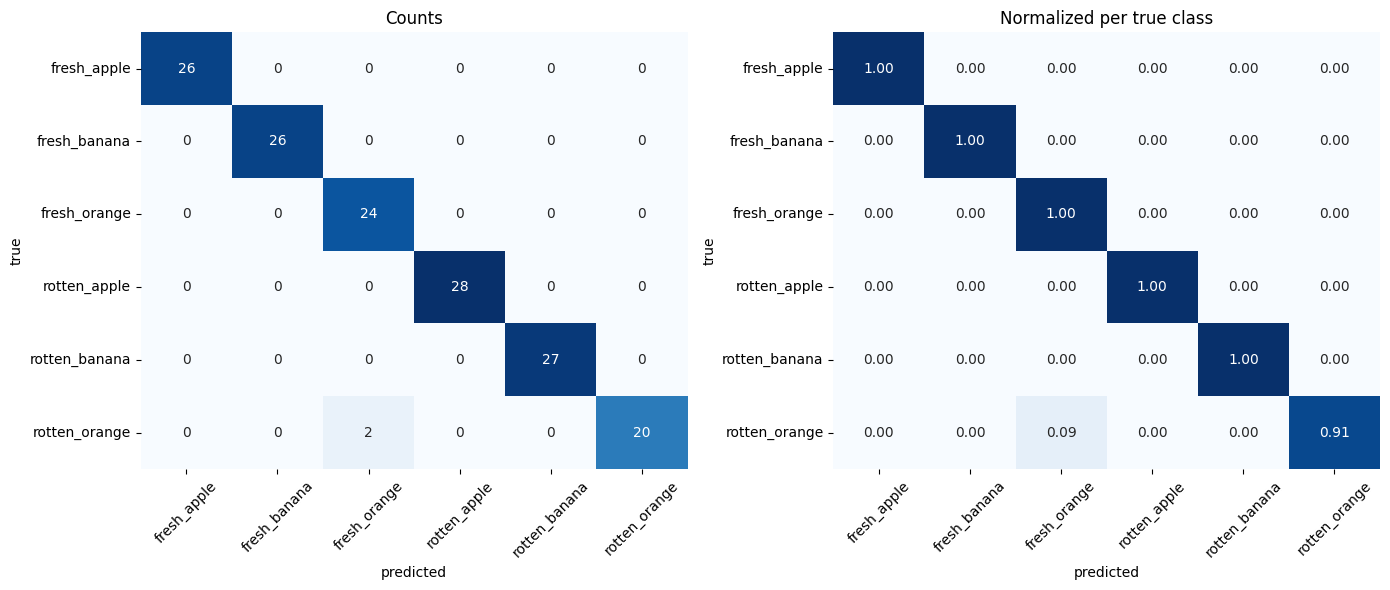

In [6]:
cm = confusion_matrix(y_true, y_pred, labels=labels)
viz.plot_confusion_matrix(cm, class_names, save_path=config.OUT_DIR / "confusion_matrix.png")
plt.show()

## Step 5 - Derived metrics: fruit type and fresh-vs-rotten
**What:** the 6-class predictions are converted to simpler questions: *which fruit is it?* (3-way) and *is it fresh or rotten?* (2-way).
**Why:** the business question is mostly "fresh or rotten?"; a model may confuse apple with orange sometimes but still get freshness right.

In [7]:
parsed = [config.parse_class_name(name) for name in class_names]       # (freshness, fruit) per class
fresh_of = np.array([p[0] for p in parsed])
fruit_of = np.array([p[1] for p in parsed])

fruit_acc = float(np.mean(fruit_of[y_true] == fruit_of[y_pred]))
fresh_acc = float(np.mean(fresh_of[y_true] == fresh_of[y_pred]))
rotten = fresh_of[y_true] == "rotten"
rotten_recall = float(np.mean(fresh_of[y_pred][rotten] == "rotten")) if rotten.any() else float("nan")
missed_rotten = int(np.sum(rotten & (fresh_of[y_pred] == "fresh")))

print(f"6-class accuracy          : {accuracy:.4f}")
print(f"Fruit-type accuracy (3-way): {fruit_acc:.4f}")
print(f"Fresh-vs-rotten accuracy  : {fresh_acc:.4f}")
print(f"Rotten recall             : {rotten_recall:.4f}  ({missed_rotten} rotten fruits passed as fresh)")
fresh_ci = train_utils.bootstrap_ci(fresh_of[y_true] == fresh_of[y_pred])
fruit_ci = train_utils.bootstrap_ci(fruit_of[y_true] == fruit_of[y_pred])
print(f"95% CI fruit-type: [{fruit_ci[0]:.4f}, {fruit_ci[1]:.4f}] | 95% CI fresh-vs-rotten: [{fresh_ci[0]:.4f}, {fresh_ci[1]:.4f}]")

6-class accuracy          : 0.9869
Fruit-type accuracy (3-way): 1.0000
Fresh-vs-rotten accuracy  : 0.9869
Rotten recall             : 0.9740  (2 rotten fruits passed as fresh)
95% CI fruit-type: [1.0000, 1.0000] | 95% CI fresh-vs-rotten: [0.9673, 1.0000]


## Step 6 - Most confident mistakes
**What:** misclassified test images, sorted by the model's confidence in the *wrong* answer.
**Why:** confident mistakes reveal systematic problems (label noise, confusing backgrounds, hard cases).

Total mistakes: 2 of 153


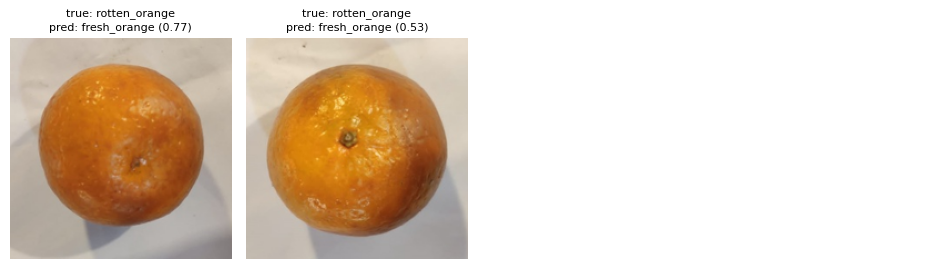

In [8]:
confidence = probs.max(axis=1)
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-confidence[wrong])][:12]
print("Total mistakes:", int((y_pred != y_true).sum()), "of", len(y_true))
if len(wrong) > 0:
    images = [data_utils.load_thumbnail(test_df.loc[i, "processed_path"], 200) for i in wrong]
    titles = [f"true: {class_names[y_true[i]]}\npred: {class_names[y_pred[i]]} ({confidence[i]:.2f})" for i in wrong]
    viz.show_image_grid(images, titles, ncols=4, save_path=config.OUT_DIR / "mistakes_gallery.png")
    plt.show()
else:
    print("No mistakes on the test set - nothing to show.")

## Step 6b - Sanity check: is the test set "too easy"? (near-duplicate analysis)
**What:** for every test image we find the most similar *training* image (smallest perceptual-hash distance, in bits out of 256). We then compare the accuracy on the half of the test images that is most similar to the training set with the other half, and show the closest test/train pairs.
**Why:** if the model were only recognising photos it had (almost) seen, accuracy would be high just for images with a close twin. The split already keeps near-duplicates (<= 10 bits) apart; this checks the softer similarity (a different photo of the same fruit) as well.

Smallest hash distance test -> train: min 11, median 20, max 94 bits (of 256)
Accuracy on the 85 test images CLOSEST to a training image : 0.9765
Accuracy on the 68 test images FARTHEST from training    : 1.0000


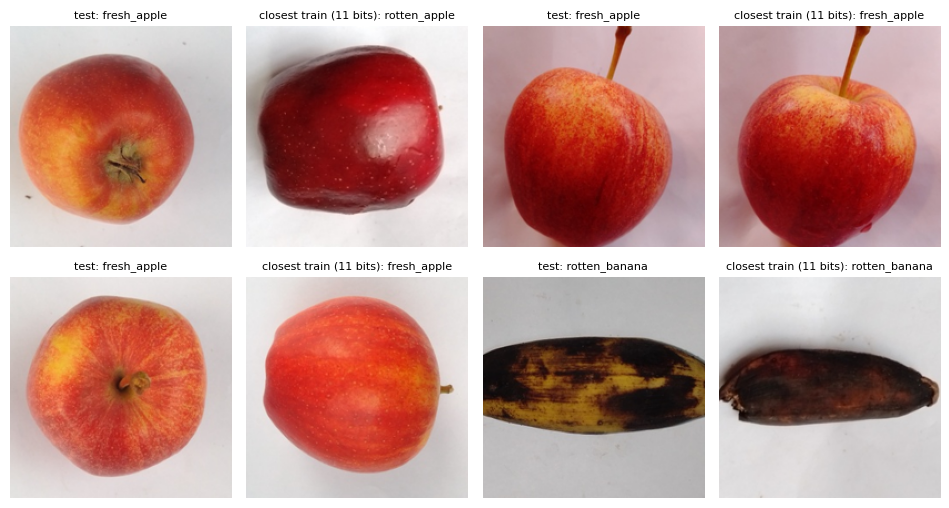

In [9]:
nearest = data_utils.nearest_train_distance(splits, "test").values       # same order as test_df
close = nearest <= np.median(nearest)                                     # the half of the test set most similar to training
print(f"Smallest hash distance test -> train: min {nearest.min()}, median {np.median(nearest):.0f}, max {nearest.max()} bits (of 256)")
print(f"Accuracy on the {int(close.sum())} test images CLOSEST to a training image : {np.mean(correct[close]):.4f}")
print(f"Accuracy on the {int((~close).sum())} test images FARTHEST from training    : {np.mean(correct[~close]):.4f}")

# closest test/train pairs side by side
test_idx = np.where(splits["split"].to_numpy() == "test")[0]
train_idx = np.where(splits["split"].to_numpy() == "train")[0]
dist = data_utils.hamming_distances(splits, test_idx, train_idx)
order = np.argsort(dist.min(axis=1))[:4]
pair_images, pair_titles = [], []
for k in order:
    j = train_idx[dist[k].argmin()]
    pair_images += [data_utils.load_thumbnail(test_df.loc[k, "processed_path"], 200),
                    data_utils.load_thumbnail(splits.loc[j, "processed_path"], 200)]
    pair_titles += [f"test: {test_df.loc[k, 'class_name']}", f"closest train ({dist[k].min()} bits): {splits.loc[j, 'class_name']}"]
viz.show_image_grid(pair_images, pair_titles, ncols=4, save_path=config.OUT_DIR / "near_duplicate_check.png")
plt.show()

## Step 7 - Grad-CAM: what does the model look at?
**What:** for a few correct and a few wrong predictions we show the cropped input next to the Grad-CAM overlay (red = most important regions for the predicted class).
**Why:** a good model should focus on the *fruit* (and its spots), not on the background.

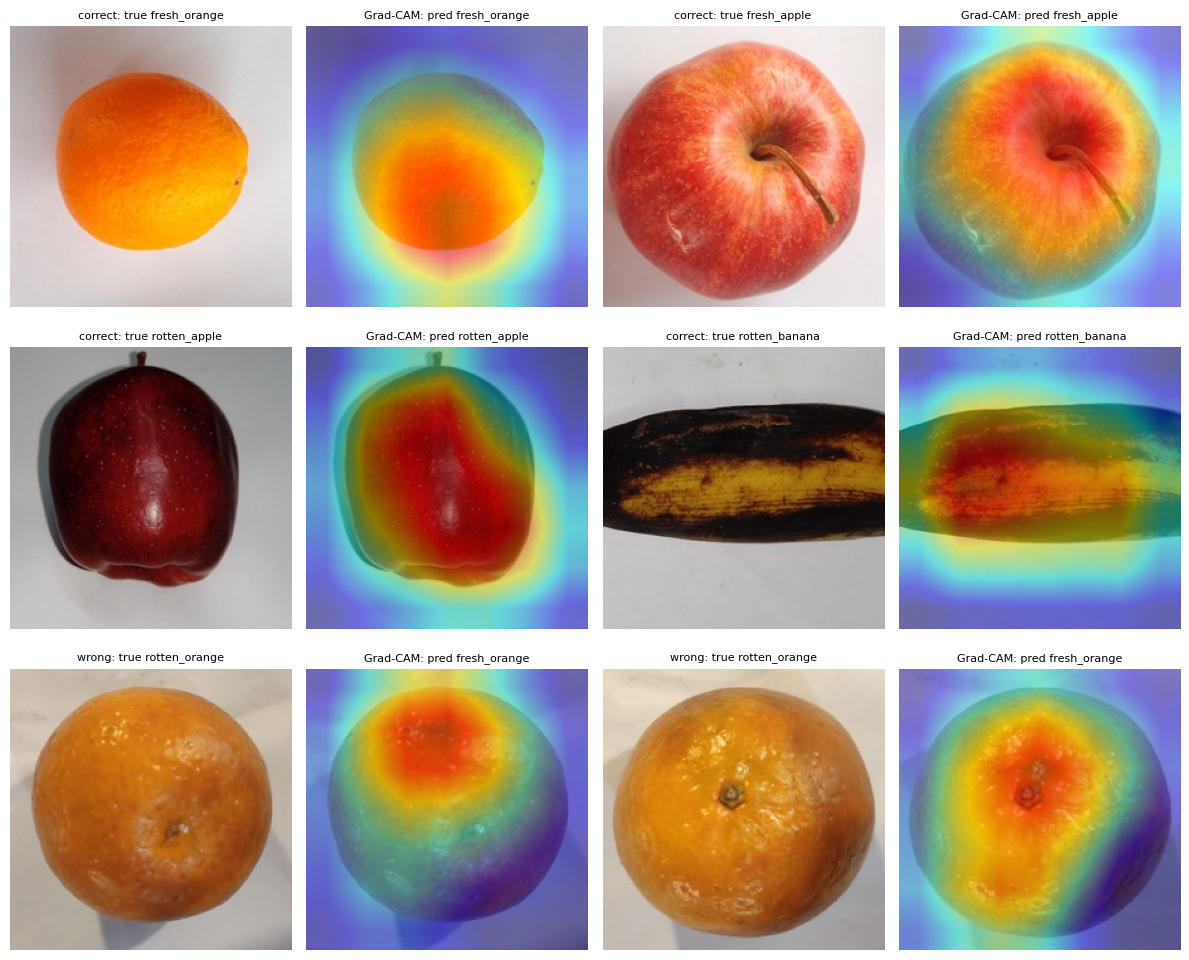

In [10]:
rng = np.random.default_rng(config.SEED)
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]
chosen = [("correct", i) for i in rng.choice(correct_idx, min(4, len(correct_idx)), replace=False)] + \
         [("wrong", i) for i in wrong_idx[np.argsort(-confidence[wrong_idx])][:4]]

images, titles = [], []
for kind, i in chosen:
    tensor = predict.preprocess_image(model, test_df.loc[i, "processed_path"])
    overlay = predict.gradcam(model, tensor)                         # explains the predicted class
    original = (transforms.denormalize(tensor[0]).permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    images += [original, overlay]
    titles += [f"{kind}: true {class_names[y_true[i]]}", f"Grad-CAM: pred {class_names[y_pred[i]]}"]
viz.show_image_grid(images, titles, ncols=4, cell=3, save_path=config.OUT_DIR / "gradcam_examples.png")
plt.show()

## Step 8 - Inference speed
Time of `predict_image` (load-free: preprocessing + forward pass + softmax) per single image, as the Task 3 app would call it.

In [11]:
sample_paths = test_df["processed_path"].head(50).tolist()
predict.predict_image(model, sample_paths[0])                        # warm-up (first call is slower)
start = time.perf_counter()
for path in sample_paths:
    predict.predict_image(model, path)
ms_per_image = (time.perf_counter() - start) / len(sample_paths) * 1000
device_name = str(next(model.parameters()).device)
print(f"{ms_per_image:.1f} ms per image on {device_name} (cached 256 px images, includes decoding)")
raw_paths = test_df["path"].head(20).tolist()                          # original huge phone photos
start = time.perf_counter()
for path in raw_paths:
    predict.predict_image(model, path)
ms_raw = (time.perf_counter() - start) / len(raw_paths) * 1000
print(f"{ms_raw:.1f} ms per image when the input is the original full-size phone photo")
print("Example output:", predict.predict_image(model, sample_paths[0]))

5.3 ms per image on cuda:0 (cached 256 px images, includes decoding)


61.7 ms per image when the input is the original full-size phone photo
Example output: {'class_name': 'fresh_apple', 'fruit': 'apple', 'freshness': 'fresh', 'confidence': 0.998892605304718, 'probabilities': {'fresh_apple': 0.998892605304718, 'fresh_banana': 7.982718670973554e-06, 'fresh_orange': 8.621011147624813e-06, 'rotten_apple': 0.0010579127119854093, 'rotten_banana': 1.1453968909336254e-05, 'rotten_orange': 2.147365376004018e-05}, 'top3': [{'class_name': 'fresh_apple', 'probability': 0.998892605304718}, {'class_name': 'rotten_apple', 'probability': 0.0010579127119854093}, {'class_name': 'rotten_orange', 'probability': 2.147365376004018e-05}]}


## Step 9 - Save the metrics

In [12]:
metrics = {
    "n_test_images": int(len(y_true)),
    "accuracy": round(accuracy, 4),
    "macro_f1": round(macro_f1, 4),
    "fruit_type_accuracy": round(fruit_acc, 4),
    "fresh_vs_rotten_accuracy": round(fresh_acc, 4),
    "rotten_recall": round(rotten_recall, 4),
    "rotten_predicted_as_fresh": missed_rotten,
    "n_mistakes": int((y_pred != y_true).sum()),
    "per_class": {name: {k: round(report[name][k], 4) for k in ["precision", "recall", "f1-score", "support"]}
                  for name in class_names},
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
    "accuracy_ci95": [round(ci_low, 4), round(ci_high, 4)],
    "fruit_type_accuracy_ci95": [round(fruit_ci[0], 4), round(fruit_ci[1], 4)],
    "fresh_vs_rotten_accuracy_ci95": [round(fresh_ci[0], 4), round(fresh_ci[1], 4)],
    "near_duplicate_check": {"n_closer_half": int(close.sum()), "n_farther_half": int((~close).sum()),
                             "acc_closer_half": round(float(np.mean(correct[close])), 4),
                             "acc_farther_half": round(float(np.mean(correct[~close])), 4),
                             "nearest_distance_bits_min_median_max": [int(nearest.min()), float(np.median(nearest)), int(nearest.max())]},
    "ms_per_image": round(ms_per_image, 2),
    "ms_per_image_full_size_photo": round(ms_raw, 2),
    "device": device_name,
}
(config.OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
print("Saved metrics.json")

Saved metrics.json


## Summary / Observations
* **Overall:** test accuracy **0.987** (151 of 153 images), macro F1 **0.985**. Bootstrap 95 % confidence interval for the accuracy: **[0.967, 1.000]**. With only 153 test images this interval is wide: one image changes the accuracy by 0.65 percentage points, so the result should be read as "about 97-100 %", not as an exact figure.
* **Per class:** apple (fresh and rotten) and banana (fresh and rotten) are perfect (F1 1.00). The only errors are **2 `rotten_orange` images predicted as `fresh_orange`** (rotten_orange recall 0.909, fresh_orange precision 0.923; F1 0.952 and 0.960).
* **Derived metrics:** fruit-type accuracy (3-way) **1.000** (the fruit is never confused with another fruit); fresh-vs-rotten accuracy (2-way) **0.987** (CI [0.967, 1.000]); rotten recall 0.974 - 2 of 77 rotten fruits were passed as fresh, which is the costly error for an inspection assistant.
* **Confusion matrix / mistakes:** both errors are rotten oranges with only mild damage (small dark patches on an otherwise orange skin), predicted fresh with low confidence (0.77 and 0.53). These are borderline cases; labels in this range are also subjective.
* **Grad-CAM:** the heat is concentrated on the fruit itself (centre, stem area and dark/rotten regions for rotten apple and banana), and the plain white background stays cold, so the model is not simply using the background. For the two wrongly classified oranges the heat sits on the top / stem area, while the few faint dark patches (lower right and edges) stay cold, which is consistent with the mistake: the model did not 'see' enough rot.
* **Leakage / "too good" check:** the score is very high, so we checked it. The split keeps near-duplicate photos together (0 pairs <= 10 hash bits). Accuracy on the half of the test set that is most similar to some training image is 0.977, on the half most different from training it is 1.000: i.e. no sign that the model only succeeds on near-copies (the two errors even occur on the 'closer' half). However, the closest test/train pairs (11 bits) show that the dataset contains several photos of similar fruit (same variety, similar background), which hashing cannot separate perfectly, so a small residual optimism remains.
* **Speed:** 5.3 ms per image on the GPU for cached 256 px images; about 62 ms when the input is the original 12-megapixel phone photo (most of the time goes into decoding and resizing the huge JPEG on the CPU). Fast enough for an interactive app.
* **Limitations:** (1) small test set (153 images, 22-28 per class); (2) all photos come from one source with clean, mostly white backgrounds, so real warehouse photos (crates, mixed fruit, other lighting) may be harder; (3) only 3 fruits and 2 freshness levels, no "partly rotten" grade; (4) hyper-parameters were chosen on the validation set only; the test set was used once for this evaluation.